# Exploring the RKHorn meson samples

Quick-look plots of the meson samples saved in `../data/pickle`. Nothing is simulated here. Write the samples first with

```
python simulate_miniboone_meson_fluxes.py
python simulate_miniboone_meson_fluxes.py --species pi_plus --horn-current 0
```

Figures are shown but not saved; the figures of the paper are made and saved by `paper_plots.ipynb`.

In [1]:
import os
import sys

from matplotlib import colors
import matplotlib.pyplot as plt
import numpy as np

sys.path.append("..")
import flux_io
from rkhorn import RKHorn

plt.style.use(os.path.abspath("../custom.mplstyle"))

NOMINAL_CURRENT = {"pi_plus": 174.0, "k_plus": 174.0, "pi_minus": -174.0}
MESON_LATEX = {"pi_plus": r"\pi^+", "k_plus": r"K^+", "pi_minus": r"\pi^-"}
COLORS = {"pi_plus": "b", "k_plus": "g", "pi_minus": "r"}

mesons = {species: flux_io.load_meson_pickle(
              flux_io.pickle_path(species, current))
          for species, current in NOMINAL_CURRENT.items()}
mesons_horn_off = flux_io.load_meson_pickle(
    flux_io.pickle_path("pi_plus", 0.0))
solver = RKHorn(horn_current=174.0)

for species, record in mesons.items():
    in_volume = record["decay_in_volume"] > 0.0
    print(f"{species:9s} produced {record['weight0'].sum():.4f} per POT, "
          f"decaying in the beamline {record['weight'][in_volume].sum():.4f}")

pi_plus   produced 0.5586 per POT, decaying in the beamline 0.1074
k_plus    produced 0.0505 per POT, decaying in the beamline 0.0168
pi_minus  produced 0.4358 per POT, decaying in the beamline 0.0738


## Where the mesons decay

Left: decay points of $\pi^+$ in the $y$-$z$ plane, weighted, with the horn outline. Only decays in the open beamline are shown. Right: the same decays along the beamline for the three species.

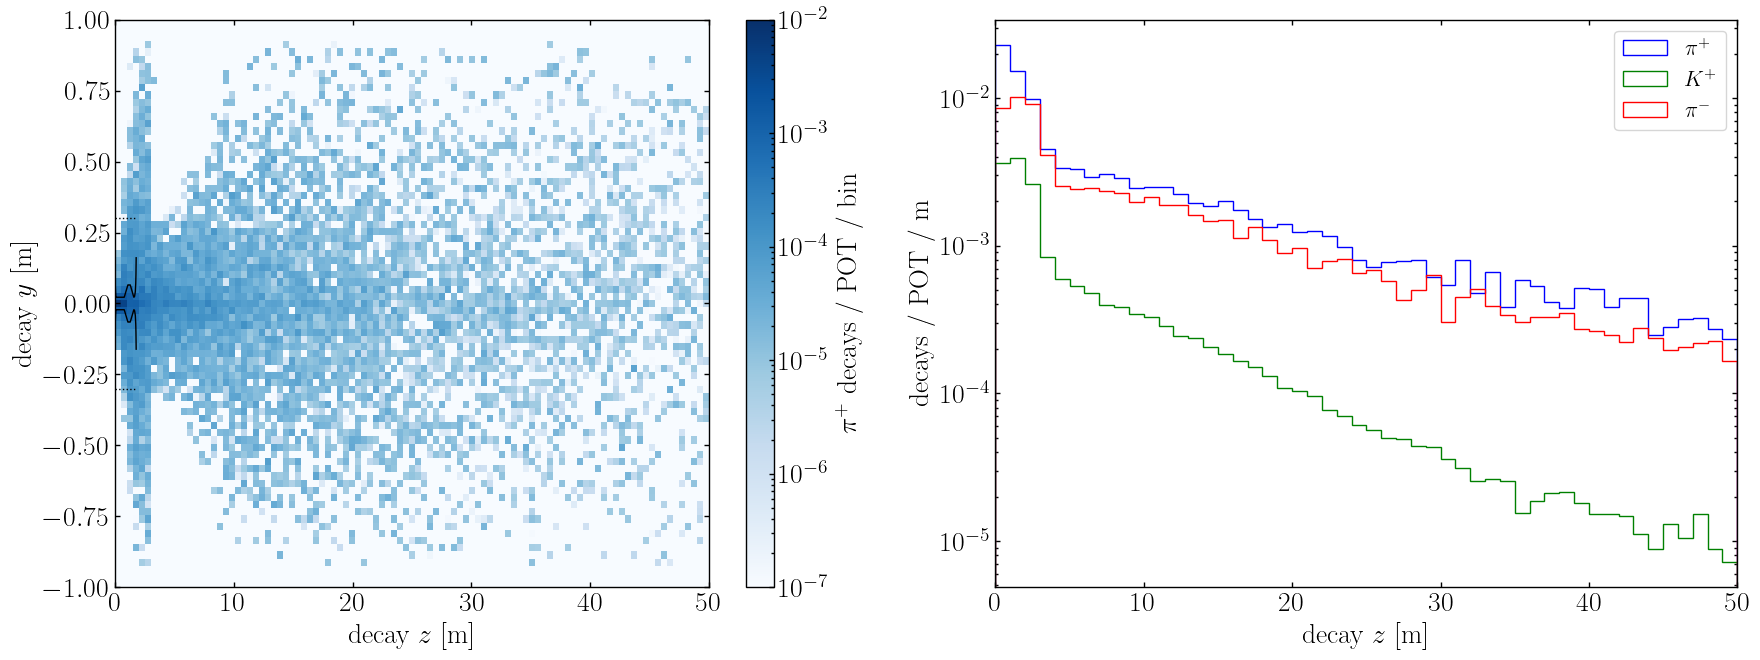

In [2]:
def draw_horn(ax: plt.Axes, solver: RKHorn) -> None:
    """Draws the horn conductors in the y-z plane.

    Args:
        ax: Axes showing y [m] against z [m].
        solver: The tracker holding the horn geometry.
    """
    z = np.linspace(solver.horn_start, solver.horn_end, 100)
    radius = solver.inner_radius(z)
    r_out = solver.horn_max_radius
    for sign in (1.0, -1.0):
        ax.plot(z, sign*radius, color="k", linewidth=1)
        ax.plot([solver.horn_start, solver.horn_end], [sign*r_out]*2,
                color="k", linewidth=1, linestyle="dotted")


record = mesons["pi_plus"]
in_volume = record["decay_in_volume"] > 0.0

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
image = axes[0].hist2d(
    record["decay_z"][in_volume], record["decay_y"][in_volume],
    weights=record["weight"][in_volume],
    bins=[np.linspace(0.0, 50.0, 100), np.linspace(-1.0, 1.0, 80)],
    cmap="Blues", norm=colors.LogNorm(vmin=1e-7, vmax=1e-2),
    rasterized=True)[3]
axes[0].set_facecolor(plt.get_cmap("Blues")(0.0))
draw_horn(axes[0], solver)
fig.colorbar(image, ax=axes[0], label=r"$\pi^+$ decays / POT / bin")
axes[0].set_xlabel(r"decay $z$ [m]")
axes[0].set_ylabel(r"decay $y$ [m]")

z_edges = np.linspace(0.0, 50.0, 51)
for species, record in mesons.items():
    in_volume = record["decay_in_volume"] > 0.0
    axes[1].hist(record["decay_z"][in_volume],
                 weights=record["weight"][in_volume], bins=z_edges,
                 histtype="step", color=COLORS[species],
                 label=rf"${MESON_LATEX[species]}$")
axes[1].set_yscale("log")
axes[1].set_xlim(z_edges[0], z_edges[-1])
axes[1].set_xlabel(r"decay $z$ [m]")
axes[1].set_ylabel("decays / POT / m")
axes[1].legend()
fig.tight_layout()
plt.show()

## Before and after the horn

For each species: the angle to the beam axis and the momentum at production, at the end of the horn tracking, and for the mesons that go on to decay in the open beamline.

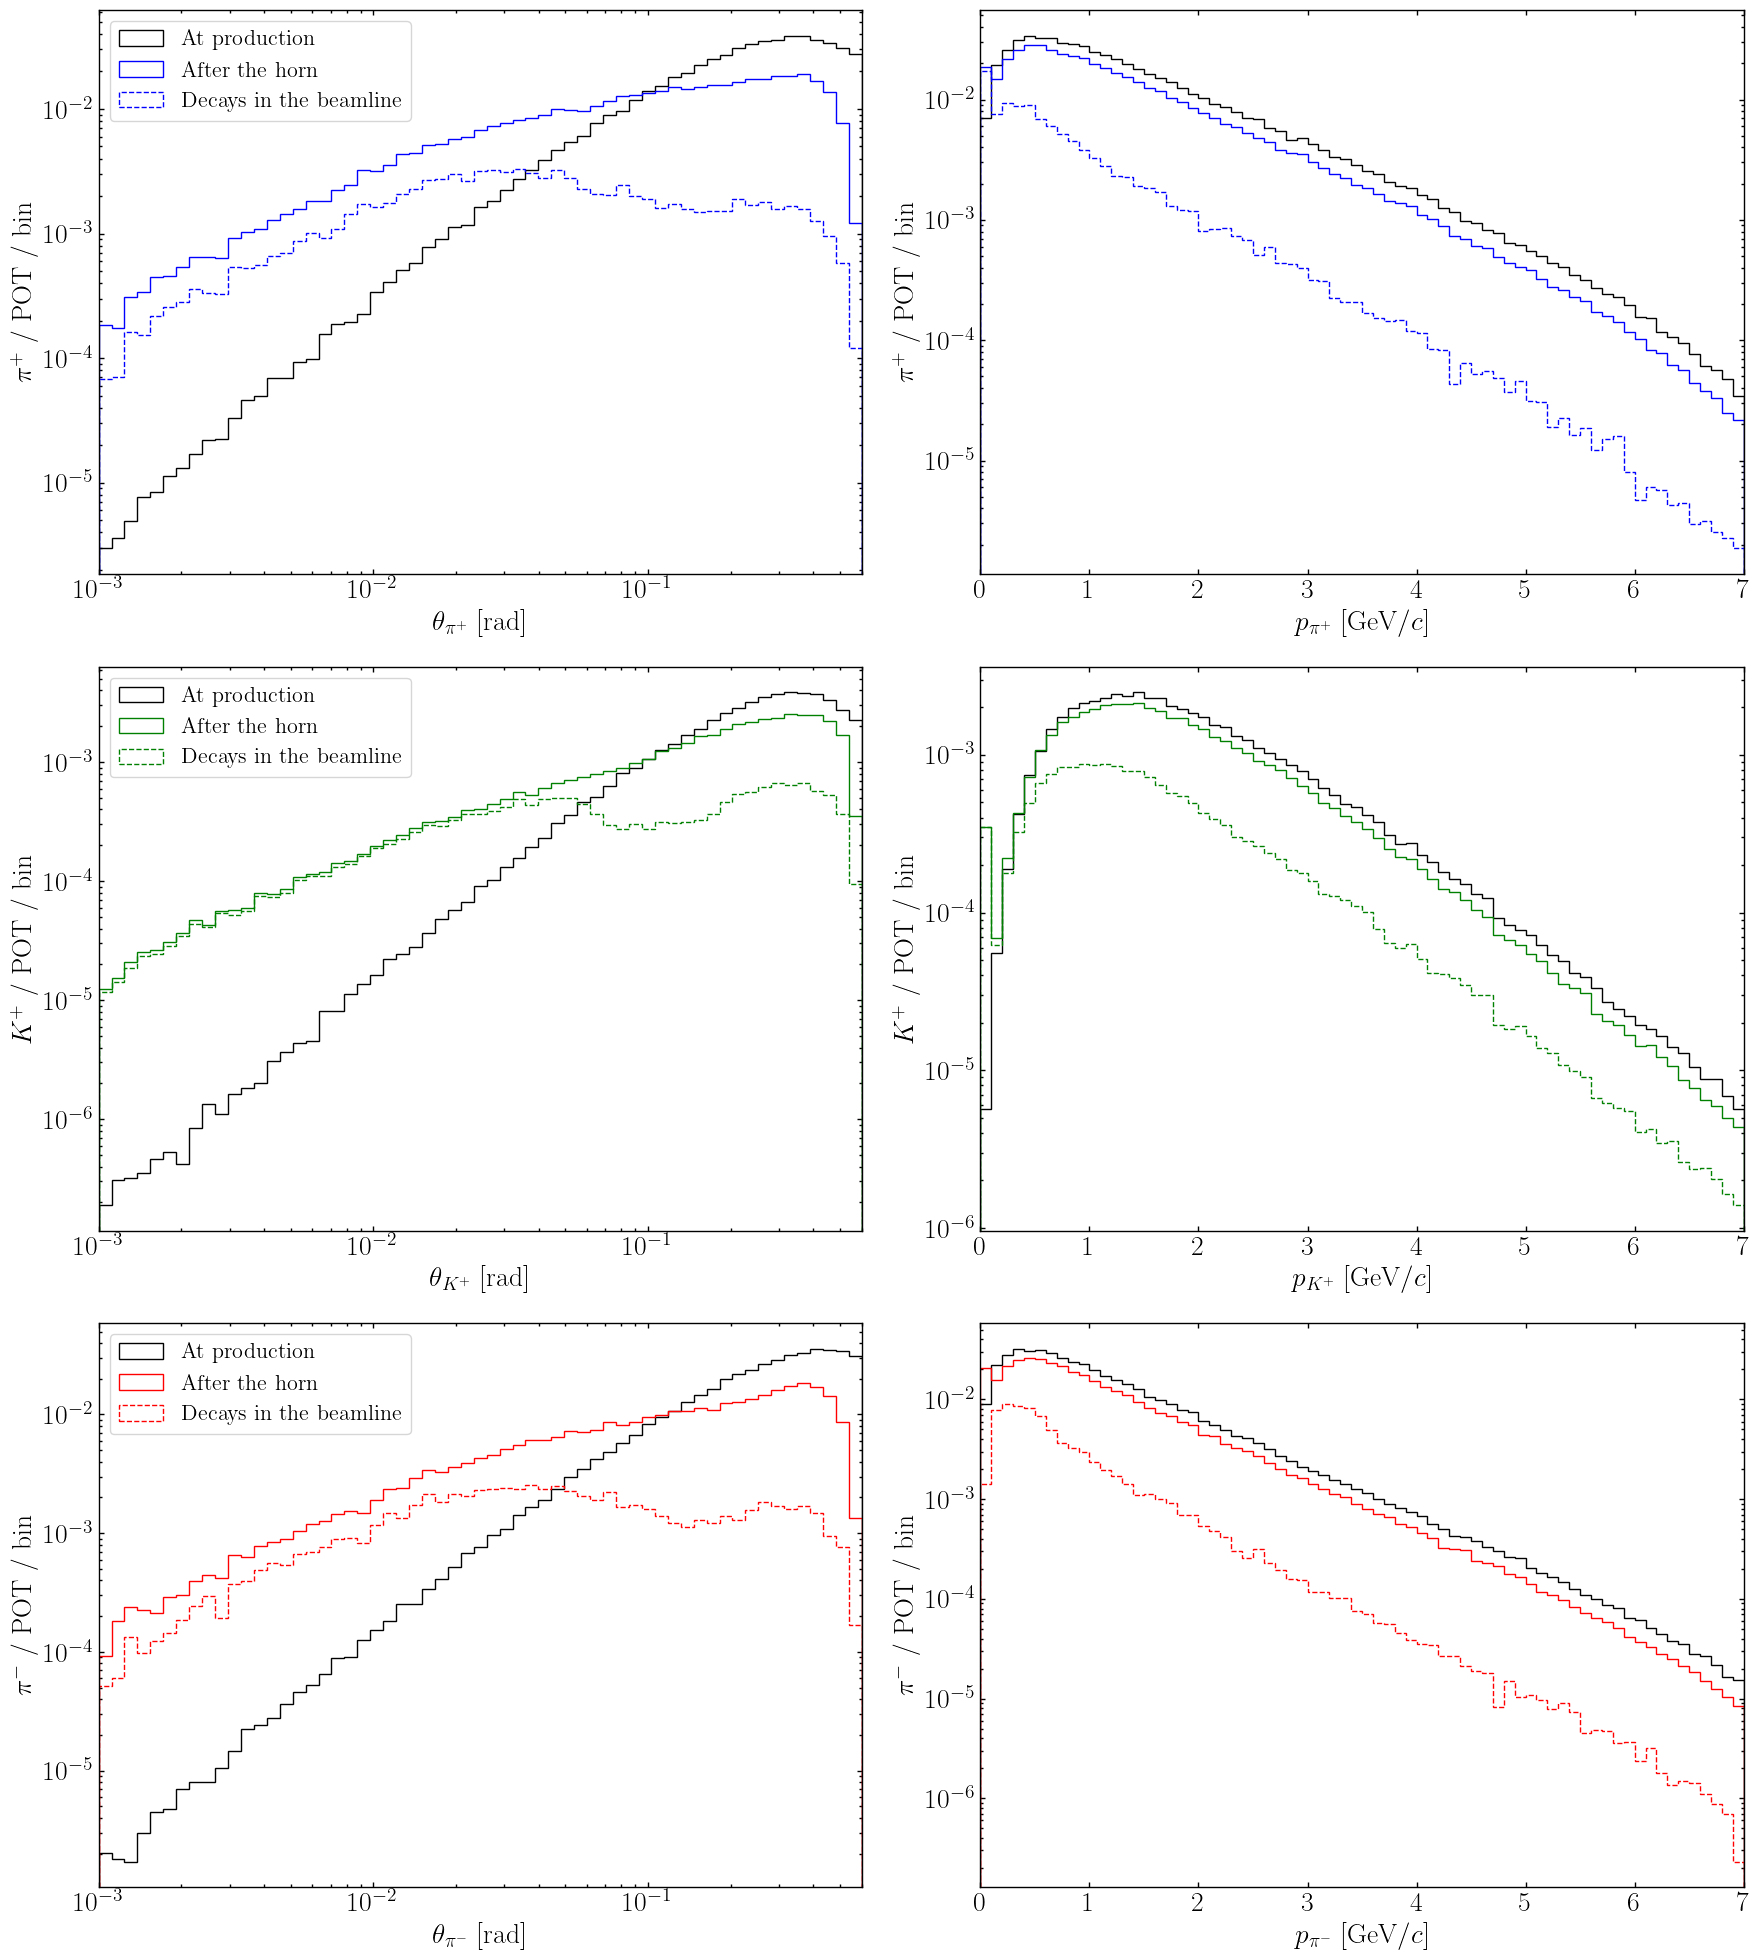

In [3]:
THETA_EDGES = np.logspace(-3, np.log10(0.6), 60)
P_EDGES = np.linspace(0.0, 7.0, 71)

fig, axes = plt.subplots(3, 2, figsize=(18, 20))
for row, (species, record) in zip(axes, mesons.items()):
    in_volume = record["decay_in_volume"] > 0.0
    samples = [
        ("At production", record["theta0"], record["p0"], record["weight0"],
         "k", "solid"),
        ("After the horn", record["theta"], record["p"], record["weight"],
         COLORS[species], "solid"),
        ("Decays in the beamline", record["theta"][in_volume],
         record["p"][in_volume], record["weight"][in_volume],
         COLORS[species], "dashed"),
    ]
    for label, theta, momentum, weight, color, linestyle in samples:
        row[0].hist(theta, weights=weight, bins=THETA_EDGES,
                    histtype="step", color=color, linestyle=linestyle,
                    label=label)
        row[1].hist(momentum*1.0e-3, weights=weight, bins=P_EDGES,
                    histtype="step", color=color, linestyle=linestyle,
                    label=label)
    meson = MESON_LATEX[species]
    row[0].set_xscale("log")
    row[0].set_yscale("log")
    row[0].set_xlim(THETA_EDGES[0], THETA_EDGES[-1])
    row[0].set_xlabel(rf"$\theta_{{{meson}}}$ [rad]")
    row[0].set_ylabel(rf"${meson}$ / POT / bin")
    row[0].legend(loc="upper left")
    row[1].set_yscale("log")
    row[1].set_xlim(P_EDGES[0], P_EDGES[-1])
    row[1].set_xlabel(rf"$p_{{{meson}}}$ [GeV$/c$]")
    row[1].set_ylabel(rf"${meson}$ / POT / bin")
fig.tight_layout()
plt.show()

## Horn on and horn off

Momentum spectrum of the $\pi^+$ that leave the horn within 50 mrad of the beam axis, with the field off and at 174 kA. The two samples contain the same produced pions.

Horn off: 0.0168 pi+/POT within 50 mrad
Horn on, $I = 174$ kA: 0.1201 pi+/POT within 50 mrad


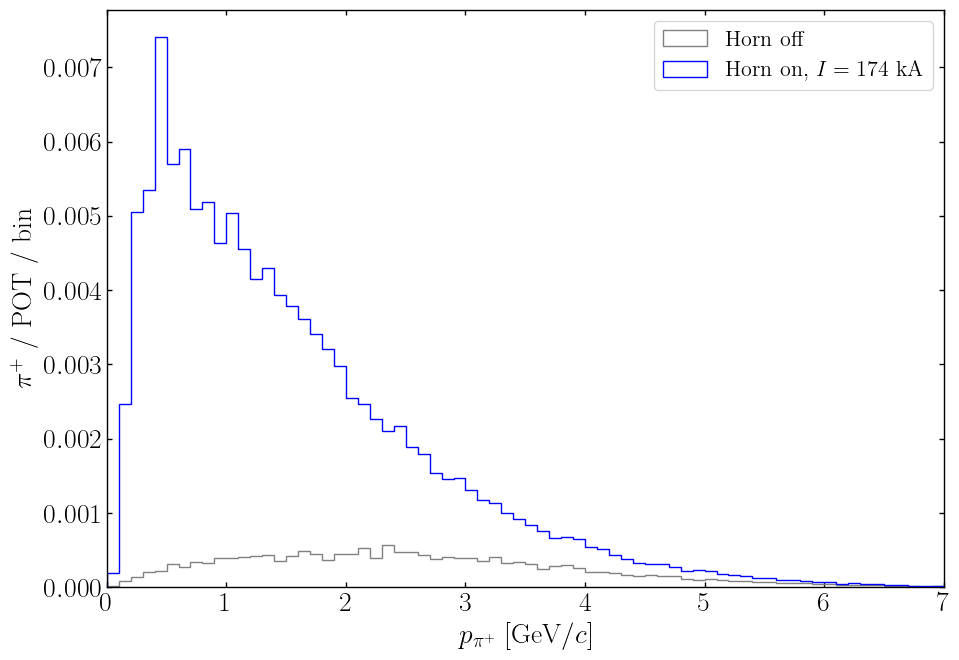

In [4]:
FORWARD_CUT = 0.05

fig, ax = plt.subplots(figsize=(10, 7))
samples = [("Horn off", mesons_horn_off, "gray"),
           (r"Horn on, $I = 174$ kA", mesons["pi_plus"], "b")]
for label, record, color in samples:
    forward = (record["theta"] < FORWARD_CUT) & (record["p"] > 0.0)
    ax.hist(record["p"][forward]*1.0e-3, weights=record["weight"][forward],
            bins=P_EDGES, histtype="step", color=color, label=label)
    print(f"{label}: {record['weight'][forward].sum():.4f} pi+/POT "
          f"within {1e3*FORWARD_CUT:.0f} mrad")
ax.set_xlim(P_EDGES[0], P_EDGES[-1])
ax.set_xlabel(r"$p_{\pi^+}$ [GeV$/c$]")
ax.set_ylabel(r"$\pi^+$ / POT / bin")
ax.legend()
fig.tight_layout()
plt.show()

## Tracks in the horn field

The saved $\pi^+$ trajectories projected onto the $y$-$z$ plane, over the $x$ component of the magnetic field in the plane $x = 0$.

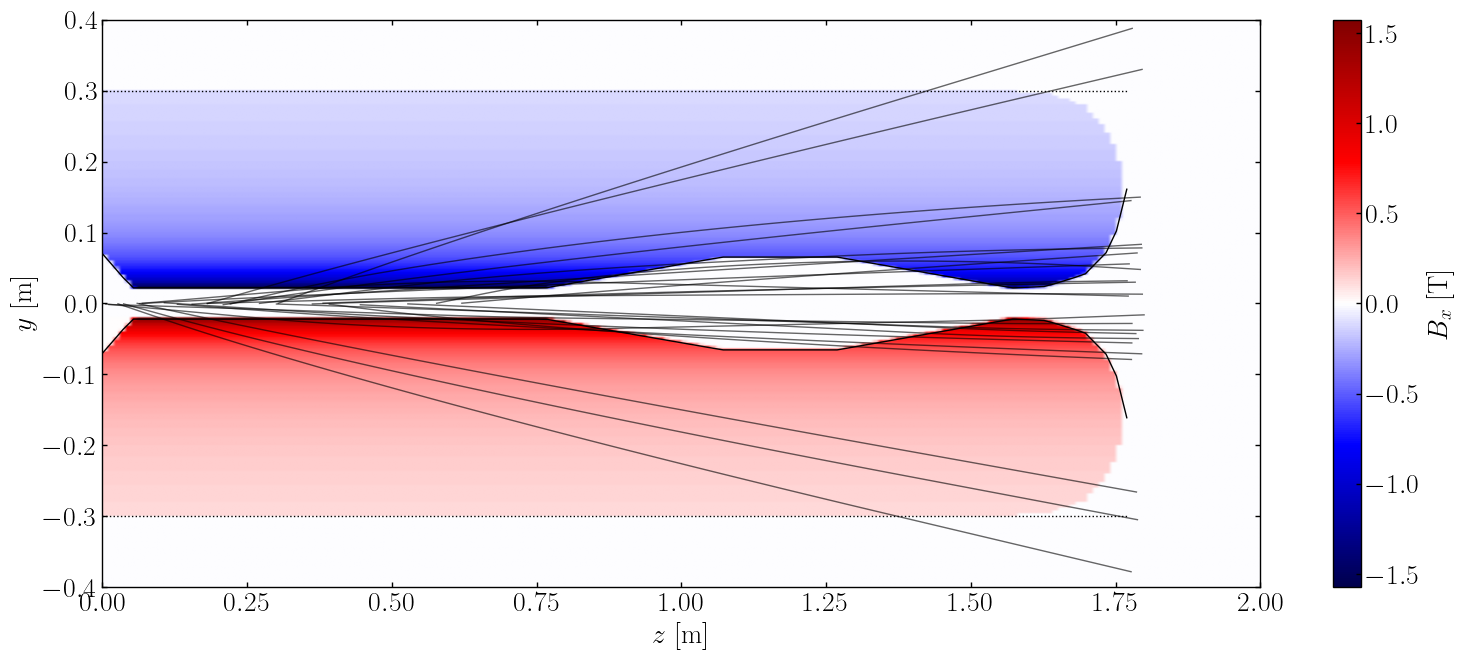

In [5]:
saved = np.load("../data/tracks/horn_3d_tracks.npz")
breaks = np.cumsum(saved["lengths"])[:-1]
track_y = np.split(saved["y"], breaks)
track_z = np.split(saved["z"], breaks)

z_fine = np.linspace(0.0, 2.0, 200)
y_fine = np.linspace(-0.4, 0.4, 200)
field_x = np.array([[solver.bfield(0.0, y, z)[0] for z in z_fine]
                    for y in y_fine])

fig, ax = plt.subplots(figsize=(16, 7))
image = ax.imshow(field_x, origin="lower", aspect="auto", cmap="seismic",
                  extent=[z_fine[0], z_fine[-1], y_fine[0], y_fine[-1]])
fig.colorbar(image, ax=ax, label=r"$B_x$ [T]")
draw_horn(ax, solver)
for y, z in zip(track_y, track_z):
    ax.plot(z, y, color="k", linewidth=1, alpha=0.6)
ax.set_xlim(z_fine[0], z_fine[-1])
ax.set_ylim(y_fine[0], y_fine[-1])
ax.set_xlabel(r"$z$ [m]")
ax.set_ylabel(r"$y$ [m]")
fig.tight_layout()
plt.show()